In [35]:
import numpy as np
import matplotlib
import math
from matplotlib import axes
from matplotlib import tri
from matplotlib import pyplot
from matplotlib import pyplot as plot
from matplotlib import pyplot as plt
from matplotlib import patches as mplp
from matplotlib import lines as mlines
#from scipy.stats import kde
%matplotlib inline

In [2]:
MiraData = np.asarray(np.genfromtxt('CleanedData_CarbonStarData.csv',delimiter=';'))

In [3]:
def mag3Point6Micron (input_array): # Take the flux in the 3.6 micron band in Jansky and return a magnitude
    mag = -2.5*np.log10(input_array/280.9) # Reference flux: 280.9±4.1
    return mag
def mag4Point5Micron (input_array):
    mag = -2.5*np.log10(input_array/179.7) # Reference flux: 179.7±2.6
    return mag
def mag5Point8Micron (input_array):
    mag = -2.5*np.log10(input_array/115.0) # Reference Flux: 115.0±1.7
    return mag
def mag8Point0Micron (input_array):
    mag = -2.5*np.log10(input_array/64.9) # Reference Flux: 64.9±0.9
    return mag
def magJ (input_array):
    mag = -2.5*np.log10(input_array/1594) # Reference Flux: 1594
    return mag
def magH (input_array):
    mag = -2.5*np.log10(input_array/1024) # Reference Flux: 1024
    return mag
def magK (input_array):
    mag = -2.5*np.log10(input_array/666.7) # Reference Flux: 666.7
    return mag

In [4]:
def Calculate3Point6Minus4Point5Color (input_array):
    mag36 = -2.5*np.log10(input_array[29]/280.9) # Reference flux: 280.9±4.1
    mag45 = -2.5*np.log10(input_array[31]/179.7) # Reference flux: 179.7±2.6
    Color = mag36-mag45
    return Color

def Calculate5Point8Minus8Point0Color (input_array):
    mag58 = -2.5*np.log10(input_array[33]/115.0) # Reference Flux: 115.0±1.7
    mag80 = -2.5*np.log10(input_array[35]/64.9) # Reference Flux: 64.9±0.9
    Color = mag58-mag80
    return Color

In [5]:
Calculate3Point6Minus4Point5Color(np.transpose(MiraData))

array([0.22904758, 0.10463989, 0.30475865, ..., 0.42881679, 0.1508293 ,
       0.13269205])

In [6]:
def CarbonStarColorSort (input_array):
    SRVList =[]
    MiraList =[]
    IDList = []
    Colors = Calculate3Point6Minus4Point5Color(input_array)
    i = 0
    while i < len(input_array[0]):
        if Colors[i] <= 0:
            SRVList.append(i)
            #IDList.append("SRV") # Is Mira is False
            IDList.append(0) # Is Mira is False
        else:
            MiraList.append(i)
            #IDList.append("Mira") # Is Mira is True
            IDList.append(1) # Is Mira is True
        i+=1
    SRV_Array = np.delete(input_array,MiraList,axis=0)
    Mira_Array = np.delete(input_array,SRVList,axis=0)
    return SRV_Array,Mira_Array, IDList

In [7]:
def DerivedMassAndRadius (input_array,Z,alpha): # Takes the Riebel data array, a metallcity input, and a mixing length input.
    i = 0
    MassArray=[]
    LArray = np.transpose(input_array)[6]
    PArray = np.transpose(input_array)[13]
    while i<len(input_array):
        L = input_array[i][6]
        P = input_array[i][13]
        # PLM Relation: logP0 = -2.285(7) - 0.826(4)logM + 2.043(3)logR
        # RLM Relation: logR = -0.323(27) + 0.737(7)logL - 0.371(14)logM
        logM = -1.859+0.951*np.log10(L)-0.631*np.log10(P)
        #logM = -3.20556+1.7326*np.log10(L)-1.36986*np.log10(P)+0.224219*np.log10(Z/0.001)-1.32493*np.log10(alpha)
        #logM = -1.5973-0.765345*np.log10(input_array[i][13]) +0.968009*np.log10(input_array[i][6]) + 0.125272*np.log10(Z/0.0124)- 0.740242*np.log10(alpha)
        #if 10**logM > 1.175:
        #    logM = -1.76005+0.968009*np.log10(L)-0.765345*np.log10(P)+0.125252*np.log10(Z/0.001)-0.740242*np.log10(alpha)
        MassArray.append(10**logM)
        i += 1
    MassArray=np.asarray(MassArray)
    RadiusArray=[]
    i=0
    while i < len(input_array):
        L = input_array[i][6]
        P = input_array[i][13]
        M = MassArray[i]
        #if M > 1.175:
        #    s = 1
        #else:
        #    s = 0
        #logR = -(-0.22584+0.02171*s) - 0.31*s*np.log10(M) + 0.68*np.log10(L) + 0.088*np.log10(Z/0.001) - 0.52*np.log10(alpha)
        # RLM Relation: logR = -0.323(27) + 0.737(7)logL - 0.371(14)logM
        logR = -0.323+0.737*np.log10(L)-0.371*np.log10(M)
        RadiusArray.append(10**logR)
        i += 1
    RadiusArray = np.asarray(RadiusArray)
    return MassArray,RadiusArray

def Calculate3Pont6Minus8Point0Color (input_array):
    mag36 = -2.5*np.log10(input_array[29]/280.9)
    mag80 = -2.5*np.log10(input_array[35]/64.9)
    Color = mag36-mag80
    return Color

In [8]:
def lum_smear (input_array): # Using the observational data and the associated error, apply a 'smearing' effect to the luminosity data
    std=np.std(np.nan_to_num(np.transpose(input_array)[7]))/np.mean(np.nan_to_num(np.transpose(input_array)[7]))
    smeared_lum = [] # An array to hold smeared luminosities
    i = 0
    while i<len(input_array): # For every i over the vertical length of the input array
        random_pm_1 = pmOneLimit(np.random.normal(0,std))
        smeared_value = input_array[i][6] + np.nan_to_num(random_pm_1*input_array[i][7]) # Smear the a luminosity by adding some factor of the error between +-1 that are normally distributed
        smeared_lum.append(smeared_value) # append the smeared luminosity to our new array
        i += 1
    return np.asarray(smeared_lum) # Return the smeared values as a numpy array

def pmOneLimit (value):
    if value > 1:
        value = 1
    elif value < -1:
        value = -1
    return value

In [9]:

TotalAdjust = 3*10**3 # This values sets the ratio between the total and dust mass loss rates
# We'll translate between Mdot_dust and Mdot using van Loon 2000 results. In that paper, this takes the form (after some manipulation)
# log Mdot = a log z +2 log Mdot_dust + C
# We have to account for differences between Carbon and other type AGB stars (mostly M). That comes in as different values of a
# (different coefficients) and potentially different values for C. log z is determined by the target. For the LMC, 
# log z = -0.45 +- 0.15. For Carbon stars, a= 1+-0.3. For other stars, a=0.7^+0.6_-0.3.
# To first order, the error is (+0.24,-0.375) +DeltaC for non-C stars and (+-0.285)+DeltaC for C stars
Cc = 2.717996149741899 # set a value for the constant in the carbon star weight. This is found by fitting to distribution.
Cm = 2.717996149741899 # Set a value for the constant in AGB star Mdot weights. This is found by fitting to distribution.

def Dust_to_Total_Mdot_trim(mdot_array,class_array): # Takes the input Mdot_dust and converts to logMdot
    i = 0
    total_mdot_array = [] # an empty list to hold modified data
    total_mdot_array_C = [] # an empty list to hold modified data
    while i<len(mdot_array):
        if class_array[i]==1: # If a Carbon star
            GaslogMdot = -(1.0)*(np.log10(0.003/0.0124))+np.log10(mdot_array[i])+Cc
            TotallogMdot = np.log10(10**GaslogMdot+mdot_array[i])
            if TotallogMdot >= -7:
                total_mdot_array_C.append(TotallogMdot)
        else: # If not a Carbon star
            GaslogMdot = -0.7*(np.log10(0.003/0.0124))+np.log10(mdot_array[i])+Cm
            TotallogMdot = np.log10(10**GaslogMdot+mdot_array[i])
            if TotallogMdot >= -7:
                total_mdot_array.append(TotallogMdot)
        i = i + 1 # Increment index
    return np.asarray(total_mdot_array), np.asarray(total_mdot_array_C)
def Dust_to_Total_Mdot(mdot_array,class_array): # Takes the input Mdot_dust and converts to logMdot
    i = 0
    total_mdot_array = [] # an empty list to hold modified data
    total_mdot_array_C = [] # an empty list to hold modified data
    while i<len(mdot_array):
        if class_array[i]==1: # If a Carbon star
            GaslogMdot = -(1.0)*(np.log10(0.003/0.0124))+np.log10(mdot_array[i])+Cc
            TotallogMdot = np.log10(10**GaslogMdot+mdot_array[i])
            total_mdot_array_C.append(TotallogMdot)
        else: # If not a Carbon star
            GaslogMdot = -0.7*(np.log10(0.003/0.0124))+np.log10(mdot_array[i])+Cm
            TotallogMdot = np.log10(10**GaslogMdot+mdot_array[i])
            total_mdot_array.append(TotallogMdot)
        i = i + 1 # Increment index
    return np.asarray(total_mdot_array), np.asarray(total_mdot_array_C)
def Observable_Trim(obsv_array,mdot_array,class_array):
    i = 0
    trimmed_obsv_array = [] # an empty list to hold modified data
    trimmed_obsv_array_C = [] # an empty list to hold modified data
    while i<len(mdot_array):
        if class_array[i]==1: # If a Carbon star
            GaslogMdot = (1.0)*(-0.45)+np.log10(mdot_array[i])+Cc
            TotallogMdot = np.log10(10**GaslogMdot+mdot_array[i])
            if TotallogMdot >= -7:
                trimmed_obsv_array_C.append(obsv_array[i])
        else: # If not a Carbon star
            GaslogMdot = 0.7*(-0.45)+np.log10(mdot_array[i])+Cm
            TotallogMdot = np.log10(10**GaslogMdot+mdot_array[i])
            if TotallogMdot >= -7:
                trimmed_obsv_array.append(obsv_array[i])
        i = i + 1 # Increment index
    return np.log10(np.asarray(trimmed_obsv_array)), np.log10(np.asarray(trimmed_obsv_array_C))

def CarbonStarSort(input_array):
    i = 0
    ListofCStars =[]
    while i<len(input_array):
        if input_array[i][1] == 1:
            ListofCStars.append(input_array[i])
        i+=1
    return ListofCStars
def NonCarbonStarSort(input_array):
    i = 0
    ListofNotCStars =[]
    while i<len(input_array):
        if input_array[i][1] != 1:
            ListofNotCStars.append(input_array[i])
        i+=1
    return ListofNotCStars
    

In [10]:
DerivedMassAndRadius(MiraData,0.003,0.75)

(array([0.82928517, 1.98471518, 2.49919211, ..., 2.45572844, 2.12034874,
        1.01447065]),
 array([147.44478157, 280.68031418, 380.69466747, ..., 328.91814279,
        273.88035108, 136.82129728]))

In [11]:
def Calculate_T_eff (LuminosityData,RadiusData): # Using Luminosity and Radius in solar units, calculate Teff in Kelvin
    Teff_array = []
    sigmaSB = 5.670373*10**(-8) # Stefan-Boltzmann constant in SI units
    i = 0
    while i < len(LuminosityData):
        Lwatts = LuminosityData[i]*(3.827*10**26) # Convert the current luminosity from solar units to Watts
        Rmeters = RadiusData[i]*(6.957*10**8) # Convert the current radius from solar units to meters
        Teff = ((Lwatts)/(4*np.pi*Rmeters**2*sigmaSB))**(0.25)
        Teff_array.append(Teff)
        i += 1
    return np.asarray(Teff_array)

In [12]:
SRVList, MiraList, IDList = CarbonStarColorSort(np.transpose(MiraData))

C:\ProgramData\Anaconda3\lib\site-packages\ipykernel_launcher.py:17: DeprecationWarning: in the future out of bounds indices will raise an error instead of being ignored by `numpy.delete`.
C:\ProgramData\Anaconda3\lib\site-packages\ipykernel_launcher.py:18: DeprecationWarning: in the future out of bounds indices will raise an error instead of being ignored by `numpy.delete`.


In [13]:
IDList[-1]

1

In [14]:
def generate_data_table (input_array,Z, alpha):
    # Using the data array and the functions above, create an array for the data we will actually use
    # Labels for data array: Name	Cl	GCl	chi2	dM/dt	e_dM/dt	Lbol	e_Lbol	Teff	e_Teff	tau	e_tau	Amp	Per	SED	FU	e_FU	FB	e_FB	FV	e_FV	FI	e_FI	FJ	e_FJ	FH	e_FH	FK	e_FK	F3.6	e_F3.6	F4.5	e_F4.5	F5.8	e_F5.8	F8.0	e_F8.0	F24	e_F24	_RA	_DE
    # This means that L_bol is at index 6 and period is at index 13
    # FJ is at index 23, FK is at index 27, F3.6 is at 29
    transposed_data = np.transpose(input_array)
    NameArray = transposed_data[0]
    print (len(NameArray))
    GClArray = transposed_data[2]
    chi2Array = transposed_data[3]
    print (len(GClArray))
    DustMassLoss = transposed_data[4]
    print (len(DustMassLoss))
    DustMassLoss_error = transposed_data[5]
    print (len(DustMassLoss_error))
    RelativeError_DustMassLoss = DustMassLoss_error/DustMassLoss
    print (len(RelativeError_DustMassLoss))
    TotalMassLoss = 10**Dust_to_Total_Mdot(DustMassLoss,GClArray)[1]
    print (len(TotalMassLoss))
    TotalMassLoss_error = 10**Dust_to_Total_Mdot(DustMassLoss_error,GClArray)[1]
    print (len(TotalMassLoss_error))
    RelativeError_Mdot = TotalMassLoss_error/TotalMassLoss
    print (len(RelativeError_Mdot))
    LBol = transposed_data[6]
    print (len(LBol))
    LBol_error = transposed_data[7]
    print (len(LBol_error))
    RelativeError_LBol = LBol_error/LBol
    print (len(RelativeError_LBol))
    SmearedLBol = lum_smear(input_array)
    print (len(SmearedLBol))
    Teff = transposed_data[8]
    print (len(Teff))
    Period = transposed_data[13]
    fluxJ = magJ(transposed_data[23]) # Col 14 - misnamed from legacy. can fix later
    fluxH = magH(transposed_data[25]) # Col 15 - misnamed from legacy. can fix later
    fluxK = magK(transposed_data[27]) # Col 16 - misnamed from legacy. can fix later
    mag36 = mag3Point6Micron(transposed_data[29]) # Column 17
    mag45 = mag4Point5Micron(transposed_data[31]) # Column 18
    mag58 = mag5Point8Micron(transposed_data[33]) # Column 19
    mag80 = mag8Point0Micron(transposed_data[35]) # Column 20
    Color36minus80 = Calculate3Pont6Minus8Point0Color(transposed_data) # Column 21
    Mass, Radius = DerivedMassAndRadius(input_array,Z,alpha) # Column 22, 23
    CalculatedTeff = Calculate_T_eff(LBol,Radius) # Column 24
    CalculatedTeff_from_smeared_L = Calculate_T_eff(SmearedLBol,Radius) # Column 25
    SRVList, MiraList, IDList = CarbonStarColorSort(np.transpose(MiraData))
    tau = transposed_data[10] # Optical Depth
    Amp = transposed_data[12]
    print (len(IDList))
    #Header = np.asarray(['Name','GRAMS Class', 'Dust Mdot', 'Total Mdot', 'L_Bol', 'Smeared L', 'Teff','P','[3.6]','[4.5]','[8.0]','[3.6]-[8.0]','M','Radius'])
    #print ('Lengths:',len(Header),len(NameArray),len(GClArray),len(DustMassLoss),len(TotalMassLoss),len(LBol),len(SmearedLBol),len(Teff),len(Period),len(mag36),len(mag45),len(mag80),len(Color36minus80),len(Mass),len(Radius))
    #new_array = np.transpose(np.vstack((NameArray,GClArray,DustMassLoss,DustMassLoss_error,RelativeError_DustMassLoss,TotalMassLoss,TotalMassLoss_error,RelativeError_Mdot,LBol,LBol_error,RelativeError_LBol,SmearedLBol,Teff,Period,fluxJ,fluxH,fluxK,mag36,mag45,mag58,mag80,Color36minus80,Mass,Radius,CalculatedTeff,CalculatedTeff_from_smeared_L,chi2Array,tau, Amp, IDList)))
    
    new_array = np.transpose(np.vstack((NameArray,GClArray,DustMassLoss,DustMassLoss_error,RelativeError_DustMassLoss,TotalMassLoss,TotalMassLoss_error,RelativeError_Mdot,LBol,LBol_error,RelativeError_LBol,SmearedLBol,Teff,Period,fluxJ,fluxH,fluxK,mag36,mag45,mag58,mag80,Color36minus80,Mass,Radius,CalculatedTeff,CalculatedTeff_from_smeared_L,chi2Array,tau,Amp)))
    print(len(np.transpose(new_array)))
    return new_array

In [15]:
ObservablePlusTable = generate_data_table (MiraData,0.003,0.75)

2069
2069
2069
2069
2069
2069
2069
2069
2069
2069
2069
2069
2069
2069
29


C:\ProgramData\Anaconda3\lib\site-packages\ipykernel_launcher.py:17: DeprecationWarning: in the future out of bounds indices will raise an error instead of being ignored by `numpy.delete`.
C:\ProgramData\Anaconda3\lib\site-packages\ipykernel_launcher.py:18: DeprecationWarning: in the future out of bounds indices will raise an error instead of being ignored by `numpy.delete`.


In [16]:
np.transpose(ObservablePlusTable)[27]

array([0.04 , 0.02 , 0.04 , ..., 0.06 , 0.01 , 0.001])

In [17]:
np.max(np.transpose(ObservablePlusTable)[-6])

506.2134819266652

In [18]:
def ErrorClean_1 (Data_Set): # A function to clear all data with unreliable values in Mdot or L
    CuttingArray = []
    i = 0
    Cleaned_Set = np.transpose(Data_Set)
    while i<len(Data_Set[3]):
        if Data_Set[3][i]/Data_Set[2][i] > 1: # If the relative error is greater than one for the dust mass-loss rate
            CuttingArray.append(i)
        elif Data_Set[9][i]/Data_Set[8][i] > 1: # If the relative error is greater than one for the luminosity
            CuttingArray.append(i)
        i += 1
    Cleaned_Set = np.delete(Cleaned_Set,CuttingArray,axis=0)
    print ('Entries Removed:',len(CuttingArray))
    print ('Stars Remaining:', len(Cleaned_Set))
    return np.transpose(Cleaned_Set)
        

In [19]:
TotalMdotIndex=5
TotalMdotErrorIndex=6
LBolIndex = 8
LBol_errorIndex = 9
TeffIndex=12
PeriodIndex=13
magJIndex=14
magHIndex=15
magKIndex=16
mag36Index=17
mag45Index=18
mag58Index=19
mag80Index=20
MassIndex=22
RadiusIndex=23
CalculatedTeffIndex=24

# We want to clean the set a bit more. This function does some additional removal of strange sources.
def ErrorClean_2 (Data_Set): # A function to clear all data with unreliable values in Mdot or L, as done by Lee Anne
    # 39 stars with logLerror = 0 ---------- Cut if logL error = 0
    # 13 remaining with logL>4.5, then ------------ Cut if logL>4.5
    # 22 with M<0.45 --------------- Cut if M<0.45
    CuttingArray = []
    i = 0
    Cleaned_Set = np.transpose(Data_Set)
    # First, deltalogL = 0 or deltalogL is nAn
    while i<len(Data_Set[LBol_errorIndex]):
        if Data_Set[LBol_errorIndex][i] == 0: # If the ith entry's error is zero
            CuttingArray.append(i)
            #print('Star cut because delta_logL is 0')
        elif np.isnan(Data_Set[LBol_errorIndex][i]) == True: # If the ith entry's error is nAn
            CuttingArray.append(i)
            #print('Star cut because delta_logL is nan')
        i += 1
    # Second, issues with logL
    i = 0
    while i<len(Data_Set[LBolIndex]):
        if np.log10(Data_Set[LBolIndex][i]) >= 4.5: # If the ith entry's luminosity is more than 10^4.5
            CuttingArray.append(i)
            #print('Star cut because logL>4.5')
        i += 1
    # Now issues with M
    i = 0
    while i<len(Data_Set[MassIndex]):
        if Data_Set[MassIndex][i] < 0.45: # If the ith entry's mass is less than 0.45
            CuttingArray.append(i)
            #print('Star cut because M<0.45')
        i += 1
    CuttingArray = np.unique(CuttingArray)
    Cleaned_Set = np.delete(Cleaned_Set,CuttingArray,axis=0)
    print ('Entries Removed:',len(CuttingArray))
    print ('Stars Remaining:', len(Cleaned_Set))
    return np.transpose(Cleaned_Set)
        

In [20]:
ObservablePlusTable=np.transpose(ErrorClean_2(ErrorClean_1(np.transpose(ObservablePlusTable))))

Entries Removed: 5
Stars Remaining: 2064
Entries Removed: 70
Stars Remaining: 1994


In [21]:
np.transpose(ObservablePlusTable)[27]

array([0.04, 0.02, 0.04, ..., 0.06, 0.06, 0.01])

In [22]:
np.savetxt('ObservablePlus_FundamentalCStarData.csv',ObservablePlusTable,delimiter=',')

In [23]:
Dust_to_Total_Mdot(np.transpose(MiraData)[4],np.transpose(MiraData)[2])[1]

array([-6.74122305, -6.74122305, -5.43505341, ..., -6.08571873,
       -7.04225304, -7.43505341])

(array([  2.,   1.,   1.,   2.,   0.,  12.,  29.,  10., 148.,  70., 128.,
        350., 377., 156., 236., 162.,  75.,  62.,  28.,  29.,  49.,  23.,
         53.,  33.,  10.,  11.,   8.,   1.,   2.,   1.]),
 array([-8.04225304, -7.92969468, -7.81713633, -7.70457797, -7.59201961,
        -7.47946126, -7.3669029 , -7.25434454, -7.14178619, -7.02922783,
        -6.91666947, -6.80411111, -6.69155276, -6.5789944 , -6.46643604,
        -6.35387769, -6.24131933, -6.12876097, -6.01620262, -5.90364426,
        -5.7910859 , -5.67852754, -5.56596919, -5.45341083, -5.34085247,
        -5.22829412, -5.11573576, -5.0031774 , -4.89061905, -4.77806069,
        -4.66550233]),
 <a list of 30 Patch objects>)

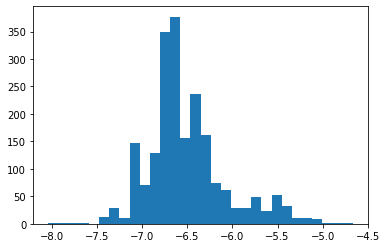

In [24]:
pyplot.hist(Dust_to_Total_Mdot(np.transpose(MiraData)[4],np.transpose(MiraData)[2])[1],30)

In [25]:
def Calculate3Point6Minus4Point5Color (input_array):
    mag36 = -2.5*np.log10(input_array[29]/280.9) # Reference flux: 280.9±4.1
    mag45 = -2.5*np.log10(input_array[31]/179.7) # Reference flux: 179.7±2.6
    Color = mag36-mag45
    return Color

def Calculate5Point8Minus8Point0Color (input_array):
    mag58 = -2.5*np.log10(input_array[33]/115.0) # Reference Flux: 115.0±1.7
    mag80 = -2.5*np.log10(input_array[35]/64.9) # Reference Flux: 64.9±0.9
    Color = mag58-mag80
    return Color

In [26]:
def ErrorClean_2 (Data_Set): # A function to clear all data with unreliable values in Mdot or L, as done by Lee Anne
    # 39 stars with logLerror = 0 ---------- Cut if logL error = 0
    # 13 remaining with logL>4.5, then ------------ Cut if logL>4.5
    # 22 with M<0.45 --------------- Cut if M<0.45
    CuttingArray = []
    i = 0
    Cleaned_Set = np.transpose(Data_Set)
    # First, deltalogL = 0 or deltalogL is nAn
    while i<len(Data_Set[9]): # 9 is the correct index for the above obervable data array
        if Data_Set[9][i] == 0: # If the ith entry's error is zero
            CuttingArray.append(i)
            print('Star cut because delta_logL is 0')
        elif np.isnan(Data_Set[9][i]) == True: # If the ith entry's error is nAn
            CuttingArray.append(i)
            print('Star cut because delta_logL is nan')
        i += 1
    # Second, issues with logL
    while i<len(Data_Set[8]): # 8 is the correct index for the above obervable data array
        if Data_Set[8][i] >= 4.5: # If the ith entry's luminosity is more than 10^4.5
            CuttingArray.append(i)
            print('Star cut because logL>4.5 is 0')
        i += 1
    # Now issues with M
    while i<len(Data_Set[19]): # 19 is the correct index for the above obervable data array
        if Data_Set[19][i] < 0.45: # If the ith entry's mass is less than 0.45
            CuttingArray.append(i)
            print('Star cut because M>0.45 is 0')
        i += 1
    CuttingArray = np.unique(CuttingArray)
    Cleaned_Set = np.delete(Cleaned_Set,CuttingArray,axis=0)
    print ('Entries Removed:',len(CuttingArray))
    print ('Stars Remaining:', len(Cleaned_Set))
    return np.transpose(Cleaned_Set)
        

In [27]:
Further_Cleaned=ErrorClean_2(np.transpose(ObservablePlusTable))

Entries Removed: 0
Stars Remaining: 1994


C:\ProgramData\Anaconda3\lib\site-packages\ipykernel_launcher.py:30: DeprecationWarning: using a non-integer array as obj in delete will result in an error in the future


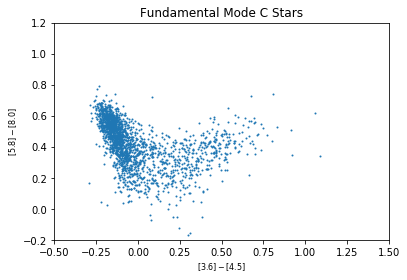

In [28]:
Color3Point6Minus4Point5 = Further_Cleaned[17]-Further_Cleaned[18]
Color5Point8Minus8Point0 = Further_Cleaned[19]-Further_Cleaned[20]

xlimits = [-0.5,1.5]
ylimits = [-0.2,1.2]

pyplot.xlim(xlimits)
pyplot.ylim(ylimits)

PxlabelText = pyplot.xlabel(r'$[3.6]-[4.5]$')
PxlabelText.set_fontsize(8) 
PylabelText = pyplot.ylabel(r'$[5.8]-[8.0]$')
PylabelText.set_fontsize(8) 
pyplot.title('Fundamental Mode C Stars')

pyplot.plot(Color3Point6Minus4Point5,Color5Point8Minus8Point0,linestyle='',ms=2,marker='.')

In [31]:
def sort_xC0(stellar_data): # Function to separate 'extreme' AGB stars from the carbon star population
    '''
    “As in Blum et al. (2006) and Srinivasan et al. (2009), we identify x-AGB stars as those brighter than the 3.6 μm TRGB and 
    with J −[3.6] > 3.1 mag. Some of the most heavily dust-enshrouded x-AGB stars are totally undetected in the near-IR. 
    Therefore, if there is no near-IR detection, but [3.6] − [8] > 0.8 and the star is brighter than the 3.6 μm TRGB, then it is
    also included in the initial list of x-AGB stars.” 
    - Boyer et. al, 2011 https://iopscience.iop.org/article/10.1088/0004-6256/142/4/103/pdf
    '''
    mag_J = stellar_data[JIndex]
    mag_36 = stellar_data[ThreePointSixIndex]
    mag_8 = stellar_data[EightPointZeroIndex]
    cut_line_1 = np.asarray([3.1,3.1])
    line_coords_1 = np.asarray([np.nanmin(mag_36 - mag_8),np.nanmax(mag_36 - mag_8)])
    # Plot 1: CCD of J-[3.6] vs [3.6]-[8.0], with cutline 1
    plot.scatter(mag_36 - mag_8, mag_J - mag_36,s=2)
    plot.plot(line_coords_1, cut_line_1)
    plot.vlines(0.8,np.nanmin(mag_J - mag_36),np.nanmax(mag_J - mag_36))
    #plot.vlines(0.7,np.nanmin(mag_J - mag_36),np.nanmax(mag_J - mag_36),linestyles='--')
    #plot.vlines(0.6,np.nanmin(mag_J - mag_36),np.nanmax(mag_J - mag_36),linestyles='--')
    plot.xlabel('[3.6]-[8.0]')
    plot.ylabel('J-[3.6]')
    #plt.gca().invert_yaxis()
    #plt.gca().invert_xaxis()
    plot.tight_layout()
    plot.show()
    plot.close()
    
    # Plot 2: CMD of [3.6] vs [3.6]-[8.0], with cutline 1
    plot.scatter(mag_36 - mag_8, mag_36,s=2)
    plot.vlines(0.8,np.nanmin(mag_36),np.nanmax(mag_36))
    #plot.vlines(0.7,np.nanmin(mag_36),np.nanmax(mag_36),linestyles='--')
    #plot.vlines(0.6,np.nanmin(mag_36),np.nanmax(mag_36),linestyles='--')
    plot.xlabel('[3.6]-[8.0]')
    plot.ylabel('[3.6]')
    plt.gca().invert_yaxis()
    #plt.gca().invert_xaxis()
    plot.tight_layout()
    plot.show()
    plot.close()
    
    # Now, the acutal sorting function
    normal_indices = []
    extreme_indices = []
    for i in range(0,np.shape(stellar_data)[1]): # Iterate over every entry in stellar_data
        if np.isnan(mag_J[i]) == False and np.isnan(mag_36[i]) == False: # If there is an entry for J and [3.6]
            if mag_J[i]-mag_36[i] > 3.1: # Stars bluer than this should be classified as extreme
                extreme_indices.append(i)
            else: # Otherwise they are not
                normal_indices.append(i)
        elif np.isnan(mag_36[i]) == False and np.isnan(mag_8[i]) == False: # If there is an entry for [3.6] and [8.0]
            if mag_36[i]-mag_8[i]>0.8:
                extreme_indices.append(i)
            else:
                normal_indices.append(i)
        else:
            normal_indices.append(i)
            print('Non-sortable star found at index ',i,'. Assumed to not be extreme.')
    
    norm_array = []
    extr_array = []
    for i in range(0, len(normal_indices)):
        norm_array.append(np.transpose(stellar_data)[normal_indices[i]])
    np_norm_array = np.asarray(norm_array)
    for i in range(0, len(extreme_indices)):
        extr_array.append(np.transpose(stellar_data)[extreme_indices[i]])
    np_extr_array = np.asarray(extr_array)
    
    mag_J_n = np.transpose(np_norm_array)[JIndex]
    mag_36_n = np.transpose(np_norm_array)[ThreePointSixIndex]
    mag_8_n = np.transpose(np_norm_array)[EightPointZeroIndex]
    mag_J_x = np.transpose(np_extr_array)[JIndex]
    mag_36_x = np.transpose(np_extr_array)[ThreePointSixIndex]
    mag_8_x = np.transpose(np_extr_array)[EightPointZeroIndex]
    
    # Plot 3: CCD of J-[3.6] vs [3.6]-[8.0], with cutline 1
    plot.scatter(mag_36_n - mag_8_n, mag_J_n - mag_36_n,s=2,label='C0')
    plot.scatter(mag_36_x - mag_8_x, mag_J_x - mag_36_x,s=2,label='C0x')
    plot.plot(line_coords_1, cut_line_1,color='black')
    plot.vlines(0.8,np.nanmin(mag_J - mag_36),np.nanmax(mag_J - mag_36))
    #plot.vlines(0.7,np.nanmin(mag_J - mag_36),np.nanmax(mag_J - mag_36),linestyles='--')
    #plot.vlines(0.6,np.nanmin(mag_J - mag_36),np.nanmax(mag_J - mag_36),linestyles='--')
    plot.xlabel('[3.6]-[8.0]')
    plot.ylabel('J-[3.6]')
    plot.legend()
    #plt.gca().invert_yaxis()
    #plt.gca().invert_xaxis()
    plot.tight_layout()
    plot.savefig('Single_Parameter_Fits/carbon_star_split_main.png',format='png')
    plot.savefig('Single_Parameter_Fits/carbon_star_split_main.pdf',format='pdf')
    plot.show()
    plot.close()
    
    # Plot 4: CMD of [3.6] vs [3.6]-[8.0], with cutline 1
    plot.scatter(mag_36_n - mag_8_n, mag_36_n,s=2,label='C0')
    plot.scatter(mag_36_x - mag_8_x, mag_36_x,s=2,label='C0x')
    plot.vlines(0.8,np.nanmin(mag_36),np.nanmax(mag_36))
    #plot.vlines(0.7,np.nanmin(mag_36),np.nanmax(mag_36),linestyles='--')
    #plot.vlines(0.6,np.nanmin(mag_36),np.nanmax(mag_36),linestyles='--')
    plot.xlabel('[3.6]-[8.0]')
    plot.ylabel('[3.6]')
    plot.legend()
    plt.gca().invert_yaxis()
    #plt.gca().invert_xaxis()
    plot.tight_layout()
    plot.savefig('Single_Parameter_Fits/carbon_star_split_secondary.png',format='png')
    plot.savefig('Single_Parameter_Fits/carbon_star_split_secondary.pdf',format='pdf')
    plot.show()
    plot.close()
    
    return np.transpose(np_norm_array), np.transpose(np_extr_array)

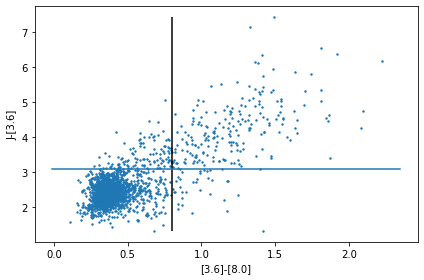

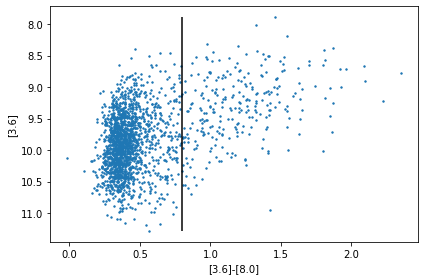

Non-sortable star found at index  226 . Assumed to not be extreme.
Non-sortable star found at index  242 . Assumed to not be extreme.
Non-sortable star found at index  249 . Assumed to not be extreme.
Non-sortable star found at index  747 . Assumed to not be extreme.
Non-sortable star found at index  916 . Assumed to not be extreme.
Non-sortable star found at index  1034 . Assumed to not be extreme.
Non-sortable star found at index  1188 . Assumed to not be extreme.
Non-sortable star found at index  1330 . Assumed to not be extreme.
Non-sortable star found at index  1338 . Assumed to not be extreme.
Non-sortable star found at index  1384 . Assumed to not be extreme.
Non-sortable star found at index  1596 . Assumed to not be extreme.


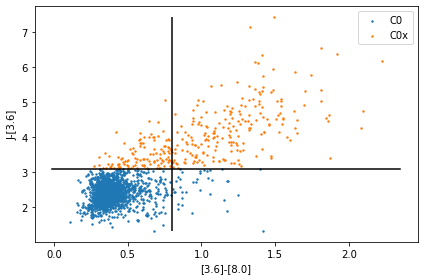

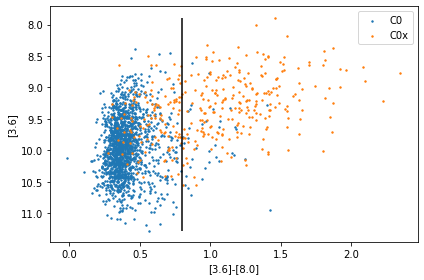

Text(0, 0.5, '$\\mathrm{Amp.}$')

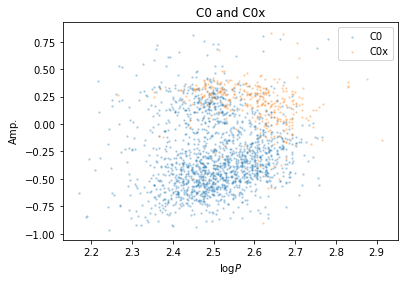

In [36]:
MdotIndex=5 # Column of imported files that has Mdot data
MdotErrorIndex=6 # Absolute error in Mdot
MdotDustIndex=2 # Column of imported files that has Mdot_dust Data
LIndex=8 # Column of imported files that has LBol data
LErrorIndex=9 # Absolute error in L
PIndex=13 # Column of imported files that has Period data
JIndex=14 # Column of imported files that has J-band magnitude
HIndex=15 # Column of imported files that has J-band magnitude
KIndex=16 # Column of imported files that has J-band magnitude
ThreePointSixIndex=17 # Column of imported files that has 3.6 band magnitude
FourPointFiveIndex=18 # Column of imported files that has 3.6 band magnitude
FivePointEightIndex=19 # Column of imported files that has 3.6 band magnitude
EightPointZeroIndex=20 # Column of imported files that has 8.0 band magnitude
MIndex=22 # Column of imported files that has Mass data
RIndex=23 # Column of imported files that has Radius data
TeffObsvIndex=12 # Column of imported files that has Observed Teff Data
TeffCalcIndex=24 # Column of imported files that has Calculated Teff Data
tauIndex=27 # Column of imported files that has Optical Depth data
AmpIndex=28 # Column of imported files that has pulsation amplitude data

C0StarData_n,C0StarData_x  = sort_xC0(np.transpose(ObservablePlusTable))

logPData_n = np.log10(C0StarData_n[PIndex])
AmpData_n = np.log10(C0StarData_n[AmpIndex])
logPData_x = np.log10(C0StarData_x[PIndex])
AmpData_x = np.log10(C0StarData_x[AmpIndex])

pyplot.scatter(logPData_n,AmpData_n,s=2,alpha=0.25,label='C0')
pyplot.scatter(logPData_x,AmpData_x,s=2,alpha=0.25,label='C0x')
plot.legend()
pyplot.title('C0 and C0x')
pyplot.xlabel(r'$\log P$')
pyplot.ylabel(r'$\mathrm{Amp.}$')